# Delivery Operations Analysis with CART

**Assessment:** Classification and Regression Trees for delivery performance.

This independently structured notebook uses a newly generated synthetic dataset. It investigates whether order and route information can (1) classify deliveries as late/on time and (2) estimate delivery duration.

**Data note:** These simulated records are for academic practice only; they are not real customer, courier, or company records. The CSV is generated separately and must be kept beside this notebook.


## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)


## 2. Load the dataset

In [2]:
df = pd.read_csv("delivery_time_dataset_original.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (8500, 11)


,Distance_km,Weather,Traffic_Level,Vehicle_Type,City_Tier,Order_Hour,Package_Weight_kg,Courier_Experience_Years,Weekend_Order,Delivery_Time_Minutes,Late_Delivery
0,36.79,Rain,Low,Bike,Tier 1,20,3.29,8,No,129.8,Yes
1,8.39,Rain,Low,Bike,Tier 1,13,3.28,8,No,54.7,Yes
2,13.95,Rain,Medium,Bike,Tier 3,15,10.58,0,No,70.3,Yes
3,21.13,Rain,Medium,Bike,Tier 1,15,1.24,14,No,90.3,Yes
4,1.02,Clear,Low,Bike,Tier 2,12,5.71,10,No,18.9,No


## 3. Inspect structure and data quality

In [3]:
display(df.dtypes.rename("data_type").to_frame())
display(pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
}))
print("Duplicate records:", df.duplicated().sum())
display(df.describe(include="all").T)


,data_type
Distance_km,float64
Weather,str
Traffic_Level,str
Vehicle_Type,str
City_Tier,str
Order_Hour,int64
Package_Weight_kg,float64
Courier_Experience_Years,int64
Weekend_Order,str
Delivery_Time_Minutes,float64


,missing_values,unique_values
Distance_km,0,3225
Weather,0,4
Traffic_Level,0,3
Vehicle_Type,0,4
City_Tier,0,3
Order_Hour,0,17
Package_Weight_kg,0,1530
Courier_Experience_Years,0,16
Weekend_Order,0,2
Delivery_Time_Minutes,0,1268


Duplicate records: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Distance_km,8500.0,NaN,NaN,NaN,16.609344,10.420229,1.0,8.9,14.4,21.9025,55.0
Weather,8500,4,Clear,4096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Traffic_Level,8500,3,Medium,3745,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,8500,4,Bike,3188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City_Tier,8500,3,Tier 1,3582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Hour,8500.0,NaN,NaN,NaN,15.080588,4.891213,7.0,11.0,15.0,19.0,23.0
Package_Weight_kg,8500.0,NaN,NaN,NaN,5.462607,3.828893,0.2,2.63,4.57,7.3725,22.0
Courier_Experience_Years,8500.0,NaN,NaN,NaN,7.581059,4.630012,0.0,4.0,8.0,12.0,15.0
Weekend_Order,8500,2,No,6033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Time_Minutes,8500.0,NaN,NaN,NaN,80.963082,26.072549,17.0,62.5,77.9,95.9,190.0


## 4. Exploratory data analysis

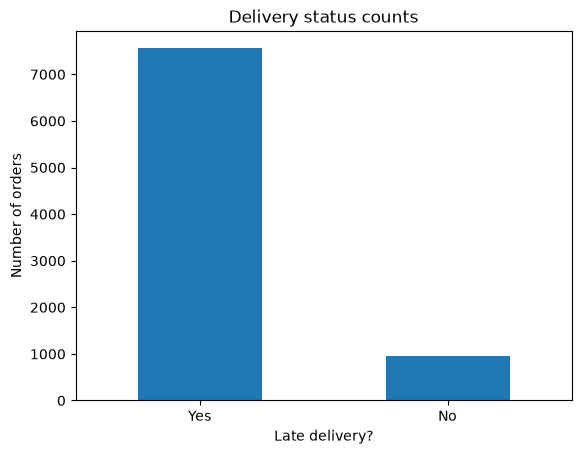

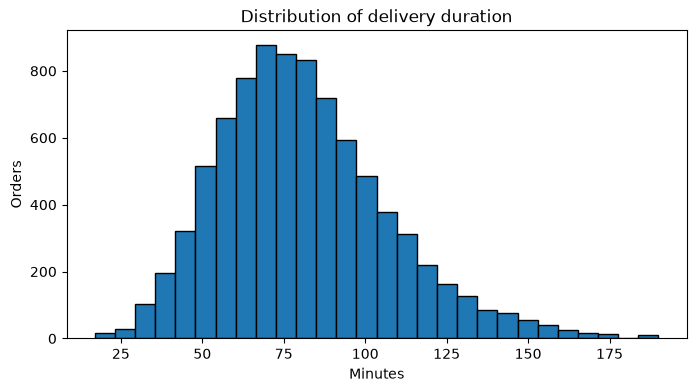

In [4]:
df["Late_Delivery"].value_counts().plot(kind="bar", rot=0, title="Delivery status counts")
plt.xlabel("Late delivery?")
plt.ylabel("Number of orders")
plt.show()

plt.figure(figsize=(8,4))
plt.hist(df["Delivery_Time_Minutes"], bins=28, edgecolor="black")
plt.title("Distribution of delivery duration")
plt.xlabel("Minutes")
plt.ylabel("Orders")
plt.show()


,average_minutes
Weather,
Clear,76.155811
Cloudy,79.805420
Rain,88.344415
Storm,96.833918


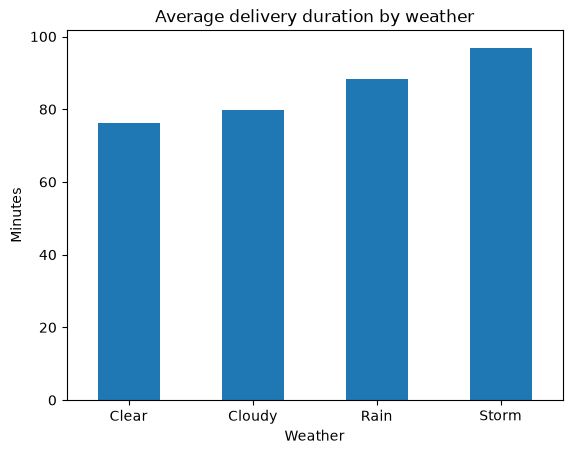

In [5]:
weather_means = df.groupby("Weather")["Delivery_Time_Minutes"].mean().sort_values()
display(weather_means.to_frame("average_minutes"))
weather_means.plot(kind="bar", rot=0, title="Average delivery duration by weather")
plt.ylabel("Minutes")
plt.show()


## 5. Define features and targets

The two target columns are not included in the model inputs. This avoids giving either model information that would reveal the answer directly.


In [6]:
input_columns = [
    "Distance_km", "Weather", "Traffic_Level", "Vehicle_Type", "City_Tier",
    "Order_Hour", "Package_Weight_kg", "Courier_Experience_Years", "Weekend_Order"
]
categorical_columns = ["Weather", "Traffic_Level", "Vehicle_Type", "City_Tier", "Weekend_Order"]
numeric_columns = ["Distance_km", "Order_Hour", "Package_Weight_kg", "Courier_Experience_Years"]

X = df[input_columns]
y_class = df["Late_Delivery"]
y_time = df["Delivery_Time_Minutes"]

print("Input dimensions:", X.shape)
print("Class balance:")
display(y_class.value_counts(normalize=True).rename("proportion").to_frame())


Input dimensions: (8500, 9)
Class balance:


,proportion
Late_Delivery,
Yes,0.888824
No,0.111176


## 6. Classification: split the records

In [7]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.25, random_state=27, stratify=y_class
)
print("Training rows:", len(X_train_c))
print("Testing rows:", len(X_test_c))


Training rows: 6375
Testing rows: 2125


## 7. Build the CART classification pipeline

One-hot encoding converts text categories into numeric indicators. The Gini criterion selects splits that reduce class impurity. The depth and leaf-size settings constrain tree complexity.


In [8]:
def build_encoder():
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numbers", "passthrough", numeric_columns)
    ])

classifier = Pipeline([
    ("encoder", build_encoder()),
    ("tree", DecisionTreeClassifier(
        criterion="gini", max_depth=5, min_samples_leaf=14,
        class_weight="balanced", random_state=27
    ))
])
classifier.fit(X_train_c, y_train_c)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoder', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Distance_km','Weather','Traffic_Level',...,'Package_Weight_kg', 'Courier_Experience_Years','Weekend_Order']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories', ...), ('numbers', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

## 8. Evaluate classification

In [9]:
pred_class = classifier.predict(X_test_c)
class_scores = pd.Series({
    "Accuracy": accuracy_score(y_test_c, pred_class),
    "Precision (late)": precision_score(y_test_c, pred_class, pos_label="Yes", zero_division=0),
    "Recall (late)": recall_score(y_test_c, pred_class, pos_label="Yes", zero_division=0),
    "F1 (late)": f1_score(y_test_c, pred_class, pos_label="Yes", zero_division=0)
})
display(class_scores.to_frame("score"))
print(classification_report(y_test_c, pred_class, zero_division=0))


,score
Accuracy,0.726588
Precision (late),0.979472
Recall (late),0.707253
F1 (late),0.821396


              precision    recall  f1-score   support

          No       0.27      0.88      0.42       236
         Yes       0.98      0.71      0.82      1889

    accuracy                           0.73      2125
   macro avg       0.63      0.79      0.62      2125
weighted avg       0.90      0.73      0.78      2125



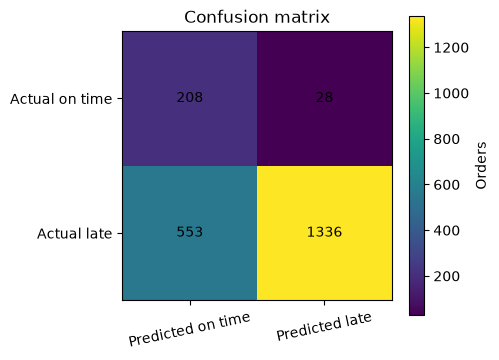

In [10]:
matrix = confusion_matrix(y_test_c, pred_class, labels=["No", "Yes"])
plt.figure(figsize=(5,4))
plt.imshow(matrix)
plt.title("Confusion matrix")
plt.xticks([0,1], ["Predicted on time", "Predicted late"], rotation=12)
plt.yticks([0,1], ["Actual on time", "Actual late"])
plt.colorbar(label="Orders")
for (row, col), value in np.ndenumerate(matrix):
    plt.text(col, row, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()


## 9. Visualize the classification tree

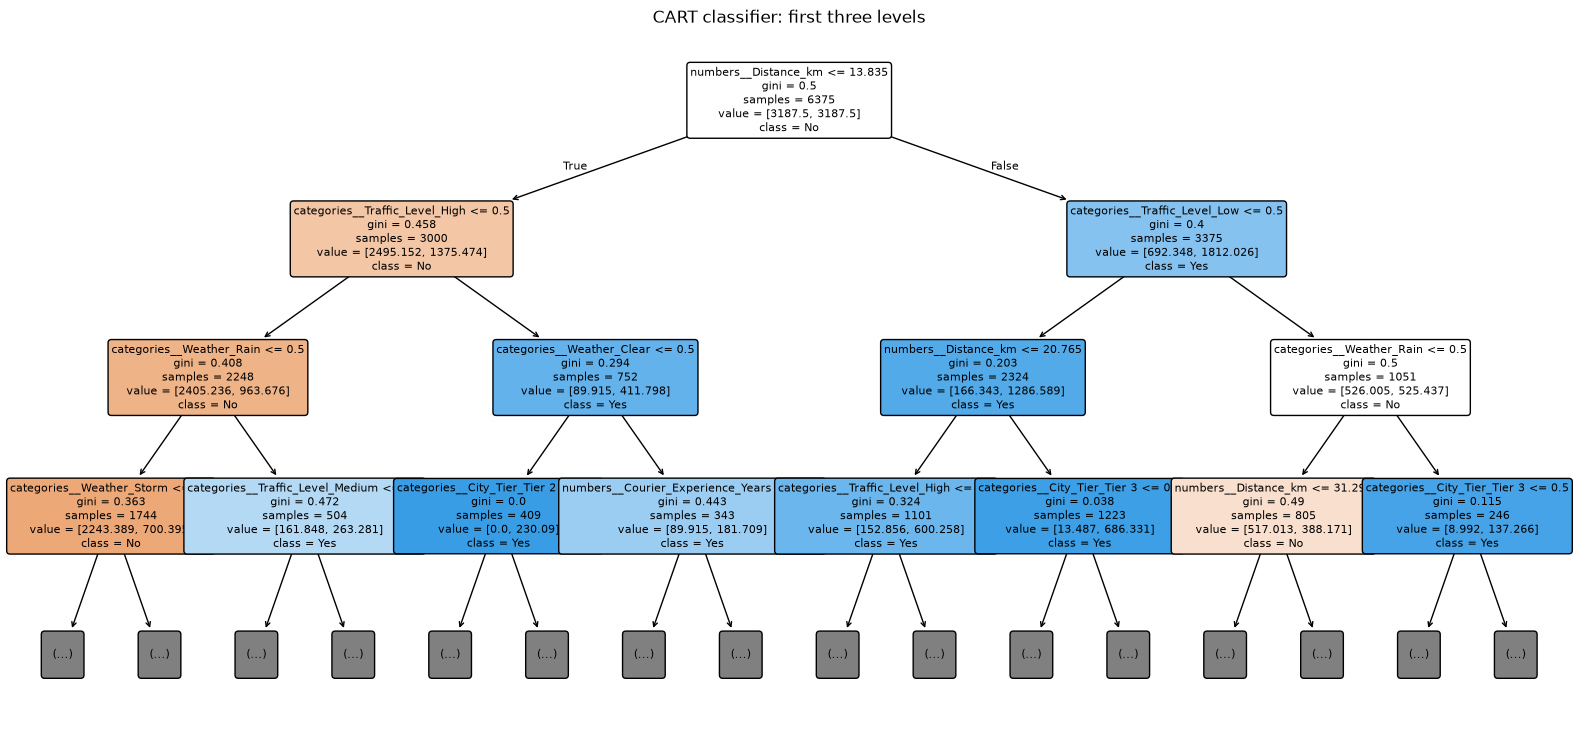

In [11]:
encoded_names = classifier.named_steps["encoder"].get_feature_names_out()
tree_classifier = classifier.named_steps["tree"]

plt.figure(figsize=(20,9))
plot_tree(tree_classifier, feature_names=encoded_names,
          class_names=tree_classifier.classes_, filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title("CART classifier: first three levels")
plt.show()


## 10. Classification feature importance

,importance
numbers__Distance_km,3.620992e-01
categories__Traffic_Level_High,1.949607e-01
categories__Traffic_Level_Low,1.280034e-01
categories__Weather_Rain,1.223009e-01
categories__Weather_Storm,7.730027e-02
categories__Traffic_Level_Medium,4.563841e-02
categories__Weather_Clear,3.619827e-02
numbers__Courier_Experience_Years,1.396982e-02
categories__City_Tier_Tier 3,9.798463e-03
numbers__Package_Weight_kg,8.205508e-03


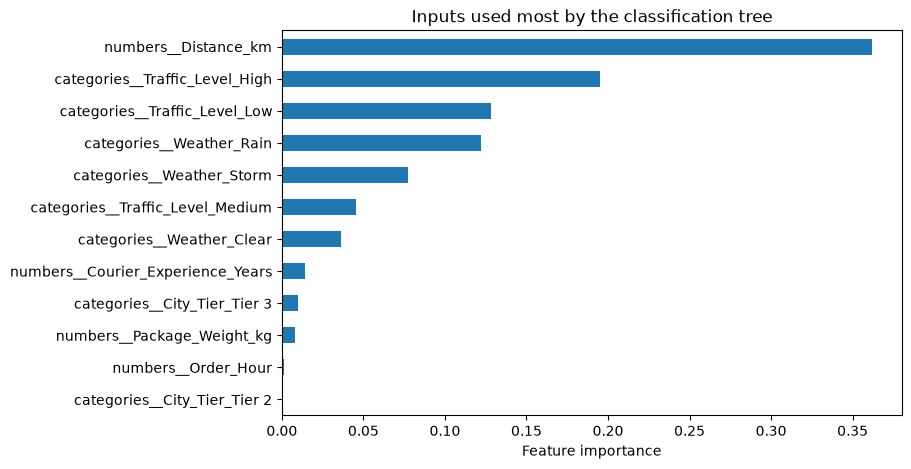

In [12]:
class_importance = pd.Series(
    tree_classifier.feature_importances_, index=encoded_names
).sort_values(ascending=False)
display(class_importance.head(12).to_frame("importance"))
class_importance.head(12).sort_values().plot(kind="barh", figsize=(8,5))
plt.title("Inputs used most by the classification tree")
plt.xlabel("Feature importance")
plt.show()


## 11. Regression: prepare the split and fit the tree

In [13]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_time, test_size=0.25, random_state=27
)

regressor = Pipeline([
    ("encoder", build_encoder()),
    ("tree", DecisionTreeRegressor(
        criterion="squared_error", max_depth=5,
        min_samples_leaf=14, random_state=27
    ))
])
regressor.fit(X_train_r, y_train_r)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoder', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Distance_km','Weather','Traffic_Level',...,'Package_Weight_kg', 'Courier_Experience_Years','Weekend_Order']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories', ...), ('numbers', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatical

## 12. Evaluate regression

In [14]:
pred_time = regressor.predict(X_test_r)
mse = mean_squared_error(y_test_r, pred_time)
regression_scores = pd.Series({
    "MAE (minutes)": mean_absolute_error(y_test_r, pred_time),
    "MSE": mse,
    "RMSE (minutes)": np.sqrt(mse),
    "R-squared": r2_score(y_test_r, pred_time)
})
display(regression_scores.to_frame("score"))


,score
MAE (minutes),9.907101
MSE,152.269629
RMSE (minutes),12.339758
R-squared,0.766092


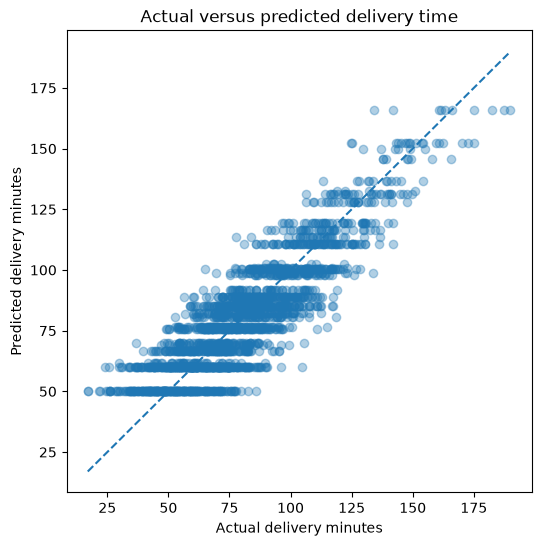

In [15]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_r, pred_time, alpha=0.35)
low = min(y_test_r.min(), pred_time.min())
high = max(y_test_r.max(), pred_time.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual delivery minutes")
plt.ylabel("Predicted delivery minutes")
plt.title("Actual versus predicted delivery time")
plt.show()


## 13. Visualize the regression tree

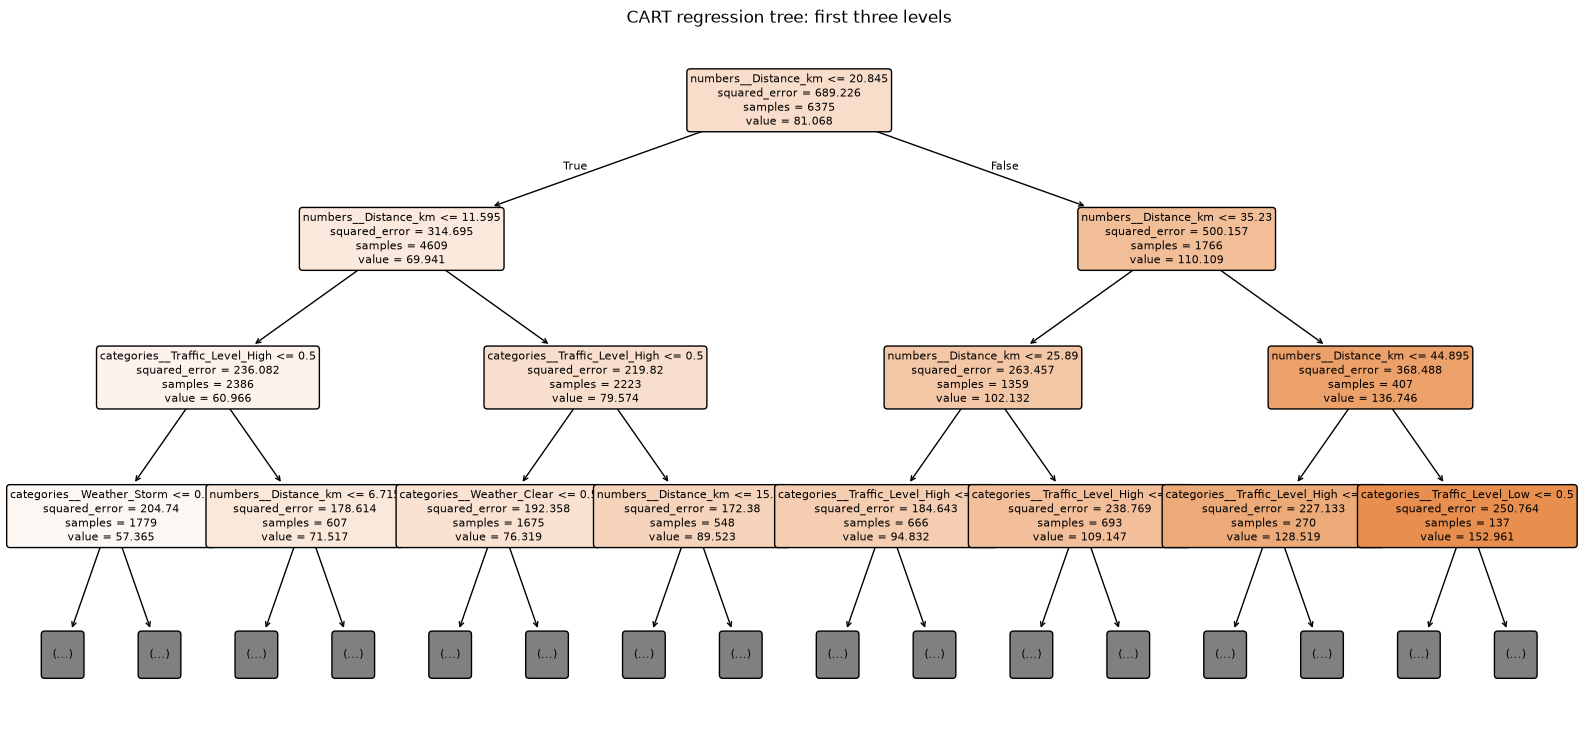

In [16]:
reg_names = regressor.named_steps["encoder"].get_feature_names_out()
tree_regressor = regressor.named_steps["tree"]
plt.figure(figsize=(20,9))
plot_tree(tree_regressor, feature_names=reg_names, filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title("CART regression tree: first three levels")
plt.show()


## 14. Experiment: does tree depth matter?

A shallow tree may underfit, while a very deep tree may overfit. Compare training and testing RMSE across several depth settings.


,max_depth,training_RMSE,testing_RMSE
0,2,15.642900,15.809318
1,3,14.133454,14.184952
2,4,12.991843,13.325080
3,5,11.993953,12.339758
4,7,10.403955,11.190597
5,None,8.703111,10.898818


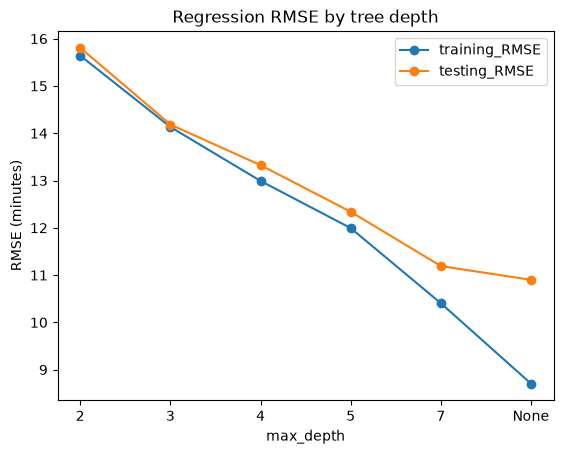

In [17]:
depth_rows = []
for depth in [2, 3, 4, 5, 7, None]:
    candidate = Pipeline([
        ("encoder", build_encoder()),
        ("tree", DecisionTreeRegressor(
            max_depth=depth, min_samples_leaf=14, random_state=27
        ))
    ])
    candidate.fit(X_train_r, y_train_r)
    train_rmse = mean_squared_error(y_train_r, candidate.predict(X_train_r)) ** 0.5
    test_rmse = mean_squared_error(y_test_r, candidate.predict(X_test_r)) ** 0.5
    depth_rows.append({
        "max_depth": str(depth),
        "training_RMSE": train_rmse,
        "testing_RMSE": test_rmse
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)
depth_results.set_index("max_depth").plot(marker="o", title="Regression RMSE by tree depth")
plt.ylabel("RMSE (minutes)")
plt.show()


## 15. Make a prediction for a new order

In [18]:
sample_order = pd.DataFrame([{
    "Distance_km": 14.2,
    "Weather": "Rain",
    "Traffic_Level": "High",
    "Vehicle_Type": "Scooter",
    "City_Tier": "Tier 1",
    "Order_Hour": 19,
    "Package_Weight_kg": 3.8,
    "Courier_Experience_Years": 4,
    "Weekend_Order": "No"
}])

print("Late delivery prediction:", classifier.predict(sample_order)[0])
print("Estimated delivery duration:", round(regressor.predict(sample_order)[0], 1), "minutes")


Late delivery prediction: Yes
Estimated delivery duration: 82.3 minutes


## 16. Conclusion

Use the metric values produced by your own run when writing your final observations.

- Classification predicts a category: late or on time. Accuracy, precision, recall, and F1-score describe different aspects of its performance.
- Regression predicts a numeric duration. MAE and RMSE are measured in minutes; R-squared summarizes explained variation.
- Tree depth controls model complexity. Compare training and testing errors to look for overfitting.
- Feature importance shows which inputs the fitted tree used for its splits. It does not prove that an input causes a delivery delay.

| Aspect | Classification | Regression |
|---|---|---|
| Target | `Late_Delivery` | `Delivery_Time_Minutes` |
| Estimator | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
| Split criterion | Gini impurity | Squared error |
| Output | Class | Numeric duration |
| Metrics | Accuracy, precision, recall, F1 | MAE, MSE, RMSE, R-squared |

